In [1]:
from pathlib import Path
import pandas as pd
from numpy import isin
import seaborn as sns
import numpy as np

import pandas as pd
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.metrics import silhouette_samples
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MultiLabelBinarizer,RobustScaler
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import RobustScaler
from scipy.cluster.hierarchy import dendrogram

## Этап 1. Загрузка и подготовка данных (6 баллов)

### Задачи
1. Загрузить CSV-файл в pandas.
2. Вывести базовую информацию о датасете: количество строк/столбцов, названия колонок, типы данных (`df.info()`, `df.head()`).
3. Преобразовать данные из широкого формата в длинный: одна строка = «регион — год», значение показателя — в отдельной колонке. Использовать `pd.melt`.
4. Привести годовые значения к числовому типу: заменить спецсимволы (например, `…`) на пропуски (`NaN`), преобразовать колонки с годами в `float`.
5. Отфильтровать регионы: оставить только те, у которых есть данные за весь период 2000–2023 (без пропусков внутри ряда). Длинные начальные пропуски не восстанавливать.
6. Перечислить в отчёте исключённые территории и обосновать причины исключения (агрегаты, дубликаты, неполные ряды).
7. Для каждого региона сформировать отдельный временной ряд (индекс — год, значения — потребление).

In [2]:
# Загружаем даннве убираем , приводим пропкски к формату NaN

datapath = Path('data')
datapath.mkdir(exist_ok=True)
file_name = 'rsdocs_1491005410458_wide_appendix_2025.csv'
df = pd.read_csv(datapath / file_name,
                encoding='utf-8',
                dtype=str,
                na_values=['…', ''])

df = df.drop(columns='Unnamed: 28')

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 96 entries, 0 to 95
Data columns (total 28 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   region_name     96 non-null     str  
 1   region_code     94 non-null     str  
 2   indicator_name  96 non-null     str  
 3   measure_unit    96 non-null     str  
 4   2000            88 non-null     str  
 5   2001            88 non-null     str  
 6   2002            88 non-null     str  
 7   2003            91 non-null     str  
 8   2004            91 non-null     str  
 9   2005            92 non-null     str  
 10  2006            92 non-null     str  
 11  2007            92 non-null     str  
 12  2008            92 non-null     str  
 13  2009            92 non-null     str  
 14  2010            92 non-null     str  
 15  2011            94 non-null     str  
 16  2012            94 non-null     str  
 17  2013            94 non-null     str  
 18  2014            96 non-null     str  
 19  

In [4]:
#удлаим общую информацию и строки где по зданию указаны пропуски
rows_to_drop = [
    'Фактическое конечное потребление домашних хозяйств на территории субъектов Российской Федерации – всего',
    'Архангельская область без автономного округа',
    'Тюменская область без автономных округов',
    'Республика Крым',
    'г. Севастополь',
]

df = df.loc[~df['region_name'].isin(rows_to_drop)]
df = df.loc[~df['region_name'].str.contains('федераль')]


#удалим все регионы с пропусками
df.dropna(inplace=True)

df.info()


<class 'pandas.DataFrame'>
Index: 78 entries, 2 to 95
Data columns (total 28 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   region_name     78 non-null     str  
 1   region_code     78 non-null     str  
 2   indicator_name  78 non-null     str  
 3   measure_unit    78 non-null     str  
 4   2000            78 non-null     str  
 5   2001            78 non-null     str  
 6   2002            78 non-null     str  
 7   2003            78 non-null     str  
 8   2004            78 non-null     str  
 9   2005            78 non-null     str  
 10  2006            78 non-null     str  
 11  2007            78 non-null     str  
 12  2008            78 non-null     str  
 13  2009            78 non-null     str  
 14  2010            78 non-null     str  
 15  2011            78 non-null     str  
 16  2012            78 non-null     str  
 17  2013            78 non-null     str  
 18  2014            78 non-null     str  
 19  2015 

In [5]:
#применяем melt и преобразуем данные из широкого формата в длинный: одна строка = «регион — год», значение показателя — в отдельной колонке. Использовать `pd.melt`.

df_long = pd.melt(
    df,
    id_vars= ['region_name', 'region_code', 'indicator_name', 'measure_unit'],  # колонки, которые нужно сохранить
    value_vars=[str(year) for year in range(2000, 2024)],  # только годовые колонки
    var_name='year',  # имя для новой колонки с названиями (по умолчанию 'variable')
    value_name="value",  # имя для новой колонки со значениями (по умолчанию 'value')
    ignore_index=True,  # сбрасывать ли индекс (по умолчанию True)
)
df_long = df_long[['region_name', 'year','value']]
df_long['value'] = pd.to_numeric(
    df_long['value'].str.replace(',', '.', regex=False), errors='coerce'
)
# Оставляем целые ряды: удаление отдельных пропусков искажает годовую динамику.
incomplete = df_long.groupby('region_name')['value'].apply(lambda s: s.isna().any())
excluded_regions = incomplete[incomplete].index.tolist()
print('Исключены регионы с неполными рядами:', excluded_regions)
df_long = df_long.loc[~df_long['region_name'].isin(excluded_regions)].copy()
df_long = df_long.sort_values(['region_name','year']).reset_index(drop=True)
df_long['year'] = df_long['year'].astype(int)

Исключены регионы с неполными рядами: []


In [6]:
df_long

,region_name,year,value
0,Алтайский край,2000,15751.1
1,Алтайский край,2001,21539.7
2,Алтайский край,2002,28855.5
3,Алтайский край,2003,35772.7
4,Алтайский край,2004,44268.9
...,...,...,...
1867,г. Санкт-Петербург,2019,573998.8
1868,г. Санкт-Петербург,2020,597721.3
1869,г. Санкт-Петербург,2021,747791.6
1870,г. Санкт-Петербург,2022,787269.0


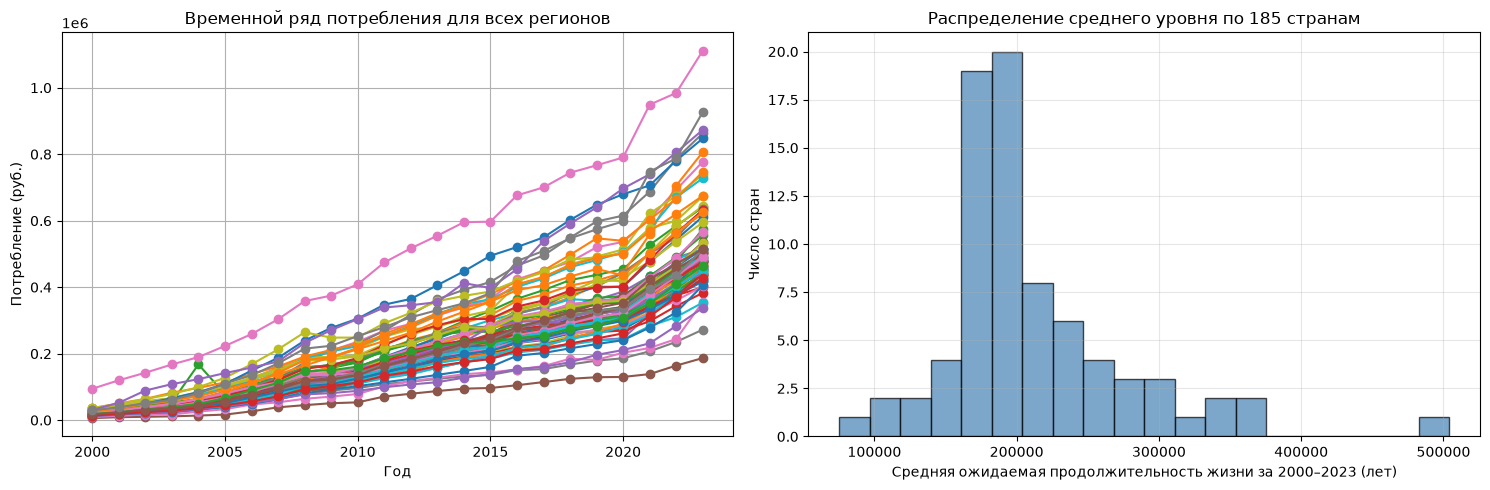

In [ ]:
# Создаем отдельные временные ряды
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

time_series = df_long.pivot(
    index='year', columns='region_name', values='value'
).sort_index()


for region in time_series.columns:
    # Исходный ряд
    axes[0].plot(time_series[region], marker='o')
axes[0].set_title(f'Временной ряд потребления для всех регионов')
axes[0].set_xlabel('Год')
axes[0].set_ylabel('Потребление (руб.)')
axes[0].grid(True)

# справа - распределение среднего уровня по странам
mean_levels = [time_series[region].mean() for region in time_series.columns]
axes[1].hist(mean_levels, bins=20, color='steelblue', edgecolor='black', alpha=0.7)
axes[1].set_title('Распределение среднего уровня по всем регионам')
axes[1].set_xlabel('аспределение среднего уровня по всем регионам')
axes[1].set_ylabel('Регионы')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Этап 2. Кластерный анализ регионов (8 баллов)

### Задачи
1. Для каждого оставшегося региона извлечь признаки на основе временного ряда. Использовать не менее 4 признаков:
   - среднее значение за период (уровень потребления);
   - коэффициент вариации (std / mean) — относительная волатильность;
   - средний годовой темп роста (или медианный темп роста);
   - относительное изменение за весь период (значение 2023 / значение 2000);
   - максимальное годовое падение (наибольшее отрицательное изменение год к году);
   - доля лет с отрицательной динамикой (число лет, когда показатель снизился относительно предыдущего года).
2. Стандартизировать признаки (например, через `StandardScaler` из scikit-learn).
3. Провести кластеризацию: можно использовать K-means или агломеративную иерархическую кластеризацию.
4. Рассмотреть варианты с 2, 3 и 4 кластерами. Для каждого варианта посчитать `silhouette_score`.
5. Выбрать оптимальное число кластеров на основе сочетания метрики и содержательной интерпретируемости групп.
6. Дать описание каждого кластера: какие регионы в него попали, средний уровень потребления, характерные особенности динамики (устойчивость, волатильность, тренды).

### Требования к отчёту
- Обосновать выбор алгоритма кластеризации.
- Привести значения `silhouette_score` для 2–4 кластеров.
- Объяснить, почему выбрано именно это число кластеров (не только по силуэту, но и по смыслу).
- Содержательно описать каждый кластер.

---

In [7]:
# Рассчитываем показатели для каждого региона


def region_stats_make(df_long):
    # Создаем временной ряд для каждого региона
    time_series = df_long.pivot(
    index='year',  # устанавливаем год как индекс
    columns='region_name',  # регионы как столбцы
    values='value'  # значения показателя
)
    # Рассчитываем показатели для каждого региона
    region_stats = []
    for region in time_series.columns:
        series = time_series[region].dropna()

        # Среднее значение
        mean_value = series.mean()

        # Коэффициент вариации
        variation_coef = series.std() / mean_value

        # Среднегодовой прирост (CAGR): степень обратна числу лет между наблюдениями.
        years = series.index[-1] - series.index[0]
        growth_rate = (series.iloc[-1] / series.iloc[0]) ** (1 / years) - 1

        # Относительное изменение
        relative_change = series.iloc[-1] / series.iloc[0]

        # Максимальное падение
        yearly_changes = series.pct_change().dropna()
        max_drop = yearly_changes.min()

        # Доля лет с отрицательной динамикой
        negative_years = (yearly_changes < 0).sum() / len(yearly_changes)

        region_stats.append({
            'region_name': region,
            'Среднее значение': mean_value,
            'Коэфф. вариации': variation_coef,
            'Среднегодовой темп роста': growth_rate,
            'Относит. изменение': relative_change,
            'Макс. падение': max_drop,
            'Доля отрицат. динамики': negative_years
        })
    region_stats = pd.DataFrame(region_stats)
    # Форматируем результаты
    region_stats['Коэфф. вариации'] = region_stats['Коэфф. вариации'] * 100
    region_stats['Среднегодовой темп роста'] = region_stats['Среднегодовой темп роста'] * 100
    region_stats['Макс. падение'] = region_stats['Макс. падение'] * 100

    return region_stats

# Выводим результаты
region_stats = region_stats_make(df_long)
region_stats

,region_name,Среднее значение,Коэфф. вариации,Среднегодовой темп роста,Относит. изменение,Макс. падение,Доля отрицат. динамики
0,Алтайский край,166038.220833,69.385702,15.311520,26.489394,-1.029618,0.043478
1,Амурская область,231900.291667,78.213754,15.874638,29.630089,3.508777,0.000000
2,Архангельская область,253850.283333,74.248898,16.106854,31.026354,3.716445,0.000000
3,Астраханская область,180520.654167,66.050339,14.702069,23.449782,0.861605,0.000000
4,Белгородская область,204367.341667,77.000531,15.314152,26.503303,5.376965,0.000000
...,...,...,...,...,...,...,...
73,Чувашская Республика,152949.233333,74.806523,16.108748,31.037993,2.255219,0.000000
74,Чукотский автономный округ,369809.887500,67.666672,15.669343,28.445933,-3.611779,0.043478
75,Ярославская область,199438.087500,74.676741,15.867348,29.587246,4.444213,0.000000
76,г. Москва,504230.937500,58.183507,11.316467,11.772441,0.281215,0.000000


### Три крупные группы по характеру динамики

`n_clusters=3` задаёт число групп, но Ward не гарантирует их размер. При стандартизации четырёх признаков динамики получаются группы из 32, 45 и 1 региона: Красноярский край выделяется из-за экстремального годового падения.

Ниже сравниваем исходный вариант с ранговым преобразованием (`QuantileTransformer`). Оно заменяет значения положением региона в распределении каждого признака и уменьшает влияние экстремальных расстояний. Таким образом, сравнивается относительный профиль динамики, а не величина различий в исходных единицах. Уровень потребления не входит в эти четыре признака, но используется для описания групп.

Для рангового варианта три группы содержат 20, 32 и 26 регионов. Их размеры не ограничены алгоритмом и могут измениться на других данных. Сравниваем также k=2 и k=4: выбор k=3 — содержательное решение для анализа трёх типов динамики, а не максимум силуэта. Метрики двух преобразований относятся к разным пространствам расстояний и не доказывают превосходство одного варианта над другим.


Компонент PCA: 3; сохранено дисперсии: 95.30%
      Преобразование  k  Silhouette               Размеры групп  Минимальный размер
StandardScaler + PCA  2    0.412267              {0: 33, 1: 45}                  33
StandardScaler + PCA  3    0.423043        {0: 32, 1: 45, 2: 1}                   1
StandardScaler + PCA  4    0.495582 {0: 15, 1: 17, 2: 1, 3: 45}                   1
         Ранги + PCA  2    0.548352              {0: 58, 1: 20}                  20
         Ранги + PCA  3    0.467032       {0: 20, 1: 32, 2: 26}                  20
         Ранги + PCA  4    0.463856 {0: 32, 1: 13, 2: 26, 3: 7}                   7

Профили трёх групп:
                 Число регионов  Среднее значение  Коэфф. вариации  Среднегодовой темп роста  Макс. падение  Доля отрицат. динамики
Кластер_3_ранги                                                                                                                    
0                            20        217944.090           67.965               

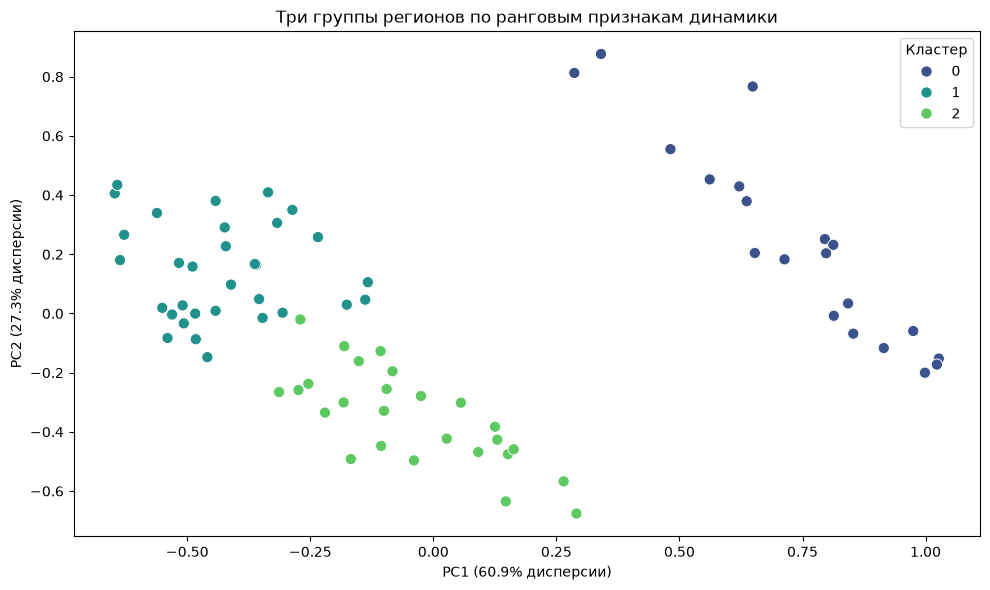

In [8]:
from sklearn.preprocessing import QuantileTransformer

# Явно задаём признаки: метки кластеров не попадают в обучение.
feature_columns = [
    'Коэфф. вариации', 'Среднегодовой темп роста',
    'Макс. падение', 'Доля отрицат. динамики',
]
X_dynamics = region_stats[feature_columns]
scaler = StandardScaler()
pca_aug = PCA(n_components=0.95)
X_scaled = pca_aug.fit_transform(scaler.fit_transform(X_dynamics))
rank_scaler = QuantileTransformer(
    n_quantiles=len(X_dynamics),
    output_distribution='uniform',
    random_state=1,
)
X_rank = rank_scaler.fit_transform(X_dynamics)
pca_rank = PCA(n_components=0.95)
X_rank_pca = pca_rank.fit_transform(X_rank)
print(f'Компонент PCA: {pca_rank.n_components_}; '
      f'сохранено дисперсии: {pca_rank.explained_variance_ratio_.sum():.2%}')

comparison = []
for space_name, features in [
    ('StandardScaler + PCA', X_scaled),
    ('Ранги + PCA', X_rank_pca),
]:
    for k in [2, 3, 4]:
        labels = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(features)
        sizes = pd.Series(labels).value_counts().sort_index()
        comparison.append({
            'Преобразование': space_name,
            'k': k,
            'Silhouette': silhouette_score(features, labels),
            'Размеры групп': sizes.to_dict(),
            'Минимальный размер': sizes.min(),
        })
        if space_name == 'Ранги + PCA' and k == 3:
            region_stats['Кластер_3_ранги'] = labels

print(pd.DataFrame(comparison).to_string(index=False))

# Профили описываем в исходных единицах, чтобы их можно было интерпретировать.
profile_columns = ['Среднее значение'] + feature_columns
profiles_3 = region_stats.groupby('Кластер_3_ранги')[profile_columns].mean()
profiles_3.insert(0, 'Число регионов', region_stats.groupby('Кластер_3_ранги').size())
print('\nПрофили трёх групп:')
print(profiles_3.round(3).to_string())
for cluster, group in region_stats.groupby('Кластер_3_ранги'):
    print(f'\nКластер {cluster} ({len(group)} регионов):')
    print(', '.join(group['region_name']))

# Первые две компоненты дают проекцию; кластеризация использует все сохранённые.
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=X_rank_pca[:, 0],
    y=X_rank_pca[:, 1],
    hue=region_stats['Кластер_3_ранги'].astype(str).to_numpy(),
    palette='viridis',
    s=65,
)
plt.xlabel(f'PC1 ({pca_rank.explained_variance_ratio_[0]:.1%} дисперсии)')
plt.ylabel(f'PC2 ({pca_rank.explained_variance_ratio_[1]:.1%} дисперсии)')
plt.title('Три группы регионов по ранговым признакам динамики')
plt.legend(title='Кластер')
plt.tight_layout()
plt.show()


## Этап 3. Выбор регионов для детального прогнозирования (5 баллов)

### Задачи
Выбрать 3 региона — по одному из разных кластеров (или 3 репрезентативных региона, если кластеров больше).

**Критерии выбора:**
- Регион должен быть репрезентативным для своего кластера (показатели близки к средним по кластеру) либо представлять крайний, но содержательно интересный случай (например, самый высокий темп роста или максимальная волатильность).
- Выбор должен отражать разнообразие динамических паттернов.

Для каждого выбранного региона привести:
- название кластера и краткое обоснование, почему регион его репрезентирует;
- базовую статистику: среднее, минимум, максимум за период;
- оценку тренда — коэффициент наклона линейной регрессии (можно через OLS или `np.polyfit`).

---


In [9]:
selected_cluster_column = 'Кластер_3_ранги'
region_stats['Итоговый кластер'] = region_stats[selected_cluster_column]

# Проверяем размеры групп
print(region_stats['Итоговый кластер'].value_counts().sort_index())

# Сравниваем характеристики
display(
    region_stats.groupby('Итоговый кластер')[
        ['Среднее значение',
         'Коэфф. вариации',
         'Среднегодовой темп роста',
         'Макс. падение',
         'Доля отрицат. динамики']
    ].mean().round(3)
)

Итоговый кластер
0    20
1    32
2    26
Name: count, dtype: int64


,Среднее значение,Коэфф. вариации,Среднегодовой темп роста,Макс. падение,Доля отрицат. динамики
Итоговый кластер,,,,,
0,217944.090,67.965,15.339,-4.967,0.046
1,206742.406,75.213,16.258,3.243,0.000
2,208302.281,69.143,14.852,2.073,0.000


In [10]:
features = [
    'Среднее значение',
    'Коэфф. вариации',
    'Среднегодовой темп роста',
    'Относит. изменение',
    'Макс. падение',
    'Доля отрицат. динамики'
]

scaled = pd.DataFrame(
    StandardScaler().fit_transform(region_stats[features]),
    index=region_stats.index,
    columns=features
)

regions_list = []

for cluster, group in region_stats.groupby('Итоговый кластер', sort=True):
    cluster_features = scaled.loc[group.index]
    center = cluster_features.mean()

    # Квадрат евклидова расстояния до центра кластера.
    distances = cluster_features.sub(center).pow(2).sum(axis=1)
    chosen_idx = distances.idxmin()
    chosen = region_stats.loc[chosen_idx, 'region_name']

    regions_list.append(chosen)
    print(f'Для кластера {cluster} выбран регион: {chosen}')

Для кластера 0 выбран регион: Ставропольский край
Для кластера 1 выбран регион: Тверская область
Для кластера 2 выбран регион: Новгородская область


## Этап 4. Анализ выбранных регионов (8 баллов)

Для каждого из трёх регионов выполнить:

1. Построить график исходного временного ряда (год — потребление). Подписать оси и заголовок.
2. Выделить тренд: использовать скользящее среднее (например, 3–5 лет) или метод Ходрика — Прескотта (опционально).
3. Проверить стационарность ряда с помощью теста Дики — Фуллера (`adfuller` из `statsmodels`). Интерпретировать p-value и сделать вывод о стационарности.
4. Построить графики ACF и PACF. На основе их вида сформулировать гипотезы о возможных порядках ARIMA (p, q).
5. Сравнить регионы между собой: у какого сильнее выражен тренд, где выше волатильность, какой ряд стационарен, как отличаются ACF/PACF. Все выводы должны опираться на графики и числа.

**Важное пояснение для отчёта:** для годовых данных сезонная декомпозиция не применяется, так как внутригодовой сезонности нет. Это нужно явно указать и обосновать.

---


Анализ региона: Ставропольский край


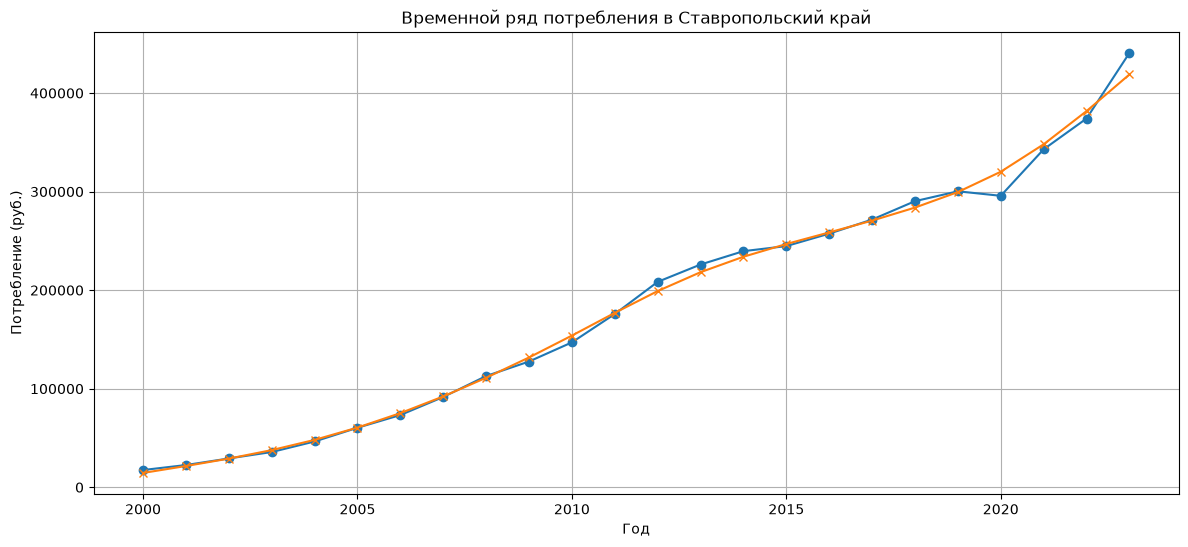

Статистика теста Дики-Фуллера: -0.765862203904777
p-значение: 0.8289447362964706
Ряд не стационарен.


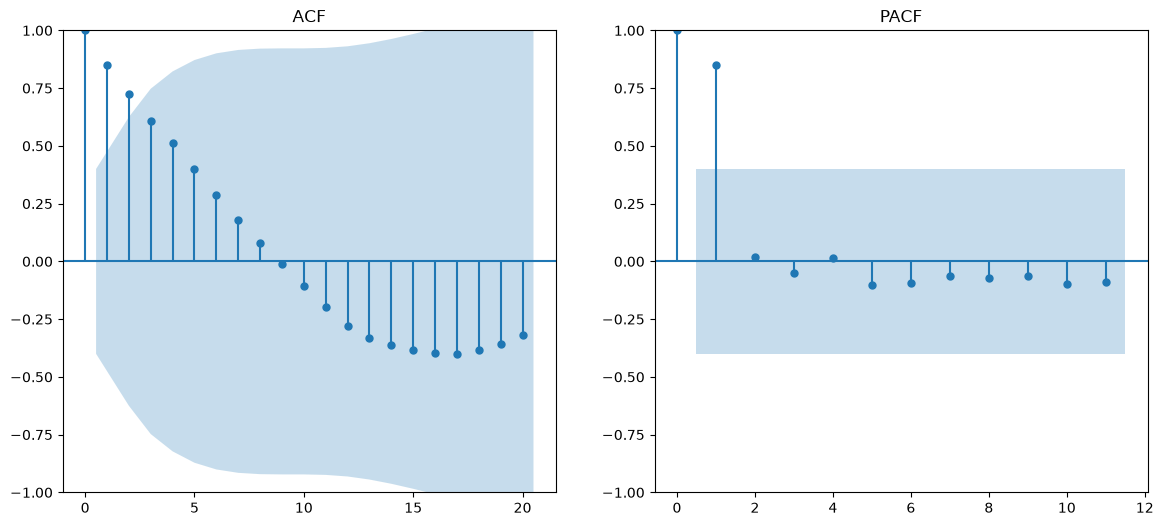

Среднее значение: 184,669.14
Стандартное отклонение: 123,577.04
Прирост за 2000–2023 гг.: 2420.10%
Среднегодовой прирост (CAGR): 15.06%



Анализ региона: Тверская область


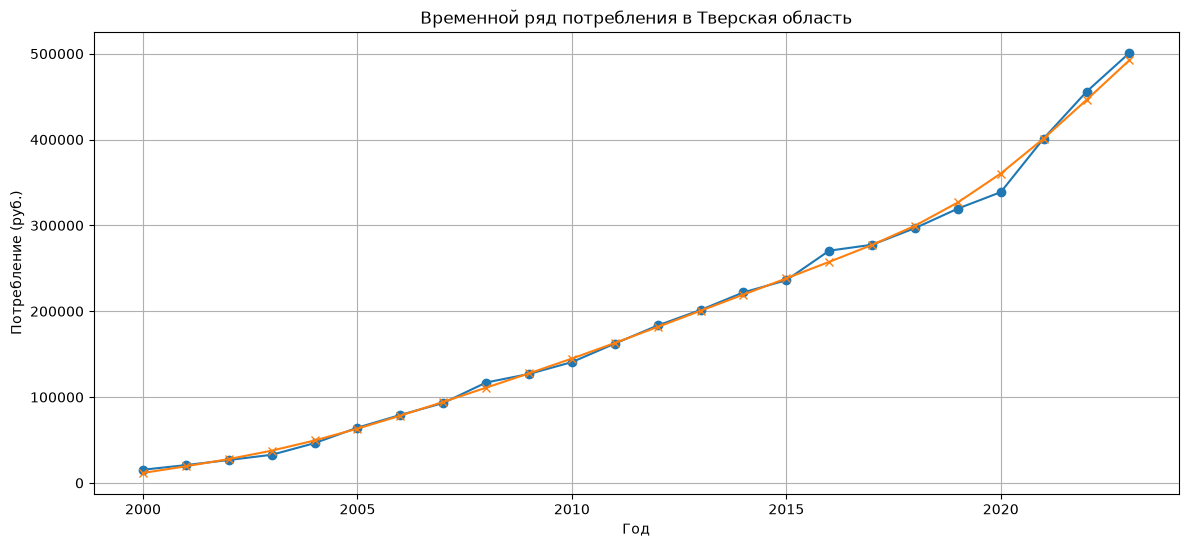

Статистика теста Дики-Фуллера: 4.856011084892601
p-значение: 1.0
Ряд не стационарен.


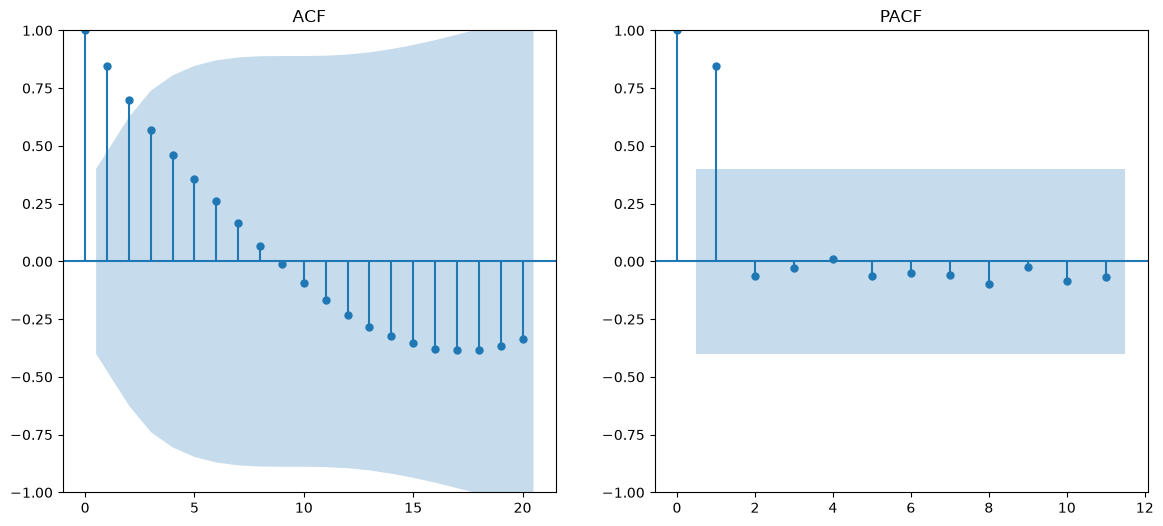

Среднее значение: 192,903.25
Стандартное отклонение: 141,505.72
Прирост за 2000–2023 гг.: 3155.12%
Среднегодовой прирост (CAGR): 16.35%



Анализ региона: Новгородская область


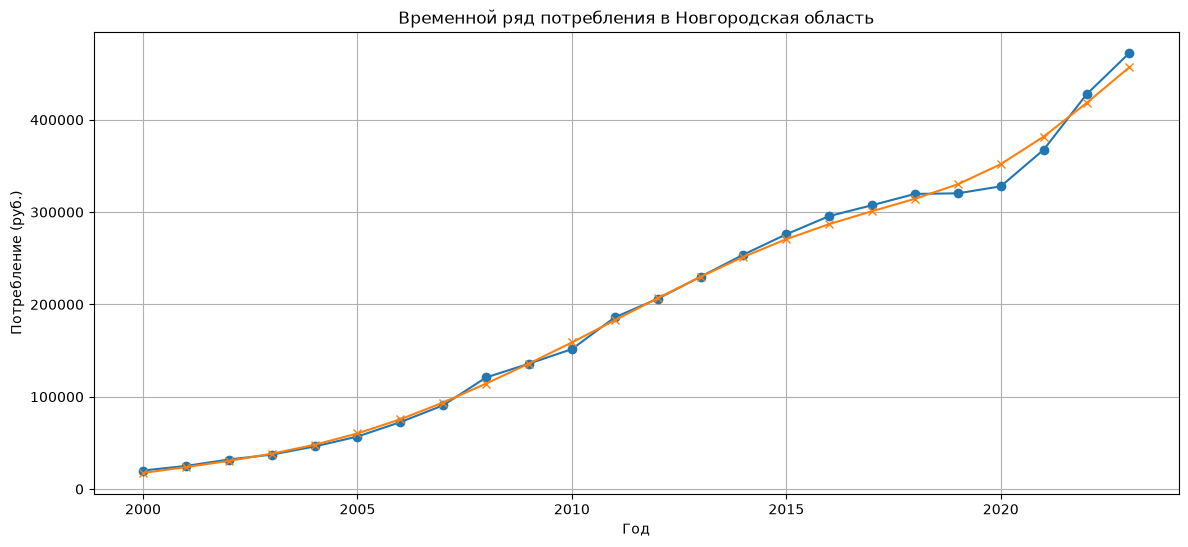

Статистика теста Дики-Фуллера: -1.9962872566072594
p-значение: 0.2882033768152704
Ряд не стационарен.


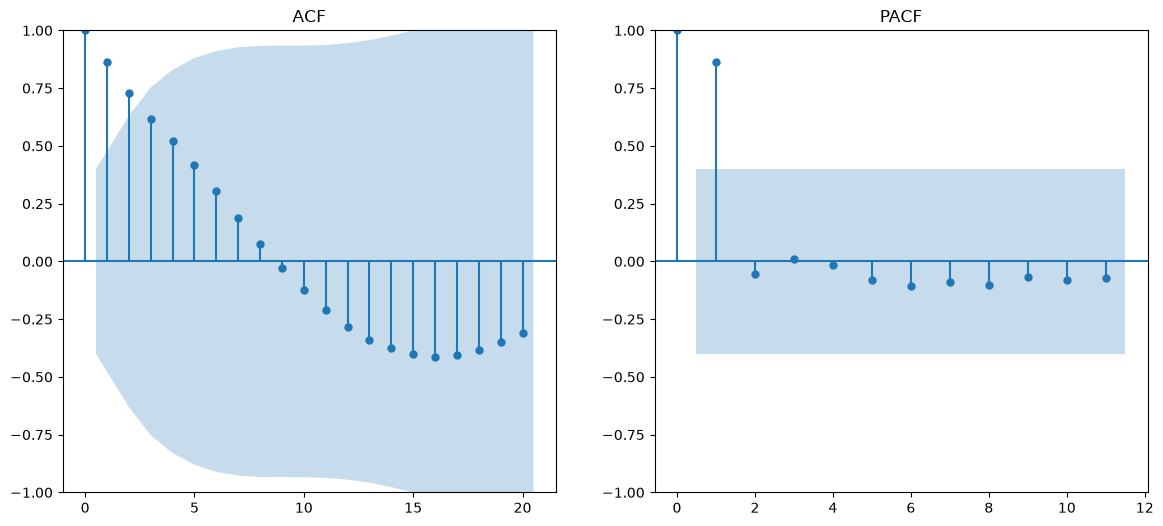

Среднее значение: 199,141.56
Стандартное отклонение: 137,126.45
Прирост за 2000–2023 гг.: 2254.39%
Среднегодовой прирост (CAGR): 14.72%




In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import statsmodels.api as sm

# Создаем отдельные временные ряды
time_series = df_long.pivot(
    index='year', columns='region_name', values='value'
).sort_index()

def adf_test(series):
    """ADF-тест с подавлением FutureWarning (result_object=True)."""
    result = adfuller(series.dropna(), autolag='AIC',
                      regression='c', result_object=True)
    p_value = result.pvalue
    is_stationary = p_value < 0.05

    print(f"Статистика теста Дики-Фуллера: {result[0]}")
    print(f"p-значение: {result[1]}")

    if is_stationary:
         print('Ряд стационарен.')
    else:
        print('Ряд не стационарен.')
    return p_value, is_stationary

def hp_filter(series, lamb=6.25):
    """Фильтр Ходрика–Прескотта для годовых данных."""
    cycle, trend = sm.tsa.filters.hpfilter(series.values, lamb=lamb)
    return pd.Series(trend, index=series.index)

# Анализ каждого региона
for region in regions_list:
    print(f"\nАнализ региона: {region}")
    # тренд
    hp_trend = hp_filter(time_series[region])
    # Исходный ряд
    plt.figure(figsize=(14, 6))
    plt.plot(time_series[region], marker='o')
    plt.plot(hp_trend, marker='x')
    plt.title(f'Временной ряд потребления в {region}')
    plt.xlabel('Год')
    plt.ylabel('Потребление (руб.)')
    plt.grid(True)
    plt.show()

    # Скользящее среднее для выявления тренда
    time_series[region + '_ma'] = time_series[region].rolling(window=3).mean()

    

    # Тест Дики-Фуллера на стационарность
    adf_test(time_series[region].dropna())


    # ACF требует лаг < n; для PACF используем лаг < n // 2.
    series = time_series[region].dropna()
    acf_lags = min(20, len(series) - 1)
    pacf_lags = min(20, len(series) // 2 - 1)

    plt.figure(figsize=(14, 6))
    plt.subplot(121)
    plot_acf(series, ax=plt.gca(), lags=acf_lags)
    plt.title('ACF')

    plt.subplot(122)
    plot_pacf(series, ax=plt.gca(), lags=pacf_lags)
    plt.title('PACF')
    plt.show()

    # Выводы
    print(f"Среднее значение: {time_series[region].mean():,.2f}")
    print(f"Стандартное отклонение: {time_series[region].std():,.2f}")
    total_growth = (series.iloc[-1] / series.iloc[0] - 1) * 100
    years = series.index[-1] - series.index[0]
    annual_growth = ((series.iloc[-1] / series.iloc[0]) ** (1 / years) - 1) * 100
    print(f"Прирост за {series.index[0]}–{series.index[-1]} гг.: {total_growth:.2f}%")
    print(f"Среднегодовой прирост (CAGR): {annual_growth:.2f}%")
    print("\n")


## Этап 5. Прогнозирование (12 баллов)

### Подготовка данных
- Разделить данные на обучающую и тестовую выборки. Обучающая — не менее 70% данных.
- Горизонт прогноза выбрать самостоятельно, но он должен быть одинаковым для всех регионов.

### Модели
Реализовать три модели:
1. **NaiveForecaster** (`strategy="last"`) из `sktime` — бейзлайн.
2. **Модель экспоненциального сглаживания с трендом (Holt)** — например, через `statsmodels.tsa.holtwinters.ExponentialSmoothing` (без сезонности, так как данные годовые).
3. **ARIMA** — через `statsmodels.tsa.arima.model.ARIMA`. Параметры можно подбирать вручную на основе ACF/PACF или автоматически (например, `auto_arima` из `pmdarima`).

### Метрики
Для каждой модели на тестовой выборке посчитать:
- RMSE;
- MAPE.

### Оценка устойчивости прогноза
Реализовать одну из стратегий:
- **Rolling forecast**: последовательно сдвигать обучающее окно на 1 шаг вперёд, переобучать модель, делать прогноз на 1 шаг, оценивать ошибку.
- **Expanding window forecast**: последовательно увеличивать обучающую выборку, сохраняя фиксированную тестовую, и смотреть, как меняется ошибка.

Применить выбранную стратегию к лучшей модели каждого региона и сравнить ошибки с фиксированным train/test. Сделать вывод об устойчивости прогноза.

### Визуализация
Построить графики:
- исторические данные;
- прогноз на тестовой выборке;
- прогноз на будущий период.

Подписи осей и заголовки обязательны.

### Выводы
Для каждого региона определить лучшую модель (по RMSE/MAPE) и обосновать, почему она сработала лучше. Учитывать, что бейзлайн — это минимальный ориентир: если статистические модели не лучше наивного прогноза, это тоже важный результат.

---

=== Разбиение train/test ===
Ставропольский край: train 17 точек (2000–2016), test 7 точек (2017–2023)
Тверская область: train 17 точек (2000–2016), test 7 точек (2017–2023)
Новгородская область: train 17 точек (2000–2016), test 7 точек (2017–2023)

=== Оценка моделей на тестовой выборке ===
              Регион Модель     Факт    Прогноз          RMSE    MAPE,%
 Ставропольский край  Naive 271635.0 257365.200  91958.940154 20.236940
 Ставропольский край   Holt 271635.0 269999.700  40403.375606  6.866499
 Ставропольский край  ARIMA 271635.0 268123.667  83614.113679 16.902658
    Тверская область  Naive 277478.1 270540.900 126621.544950 23.717434
    Тверская область   Holt 277478.1 292185.595  34318.485919  7.422058
    Тверская область  ARIMA 277478.1 291115.028 111180.391755 19.320459
Новгородская область  Naive 307446.2 295682.800  89549.905033 16.665550
Новгородская область   Holt 307446.2 317171.332  30666.012950  7.633776
Новгородская область  ARIMA 307446.2 301663.511  85126.8872

/home/alex/Yandex.Disk/mystuff/MIFI/time_row_exam/.venv/lib/python3.12/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sktime 1.3.0. After 1.3.0, ``BaseForecaster`` will no longer store incremental data in ``_X`` and ``_y`` by default. To silence this warning and adopt the new default early, set ``remember_data=False`` via ``set_config``. For forecasters that do not have update natively supported, i.e., the capability:update tag is not True, the default ``update`` will not refit. To keep storing incremental data and refitting on every update after the default change, set ``remember_data=True`` explicitly, or use ``UpdateRefitsEvery`` with ``refit_interval=0``.
  warn(
/home/alex/Yandex.Disk/mystuff/MIFI/time_row_exam/.venv/lib/python3.12/site-packages/sktime/forecasting/base/_base.py:169: FutureWarning: The default of config ``remember_data`` will change from ``True`` to ``False`` in sk


=== Устойчивость прогноза (expanding window) ===
              Регион Модель  Итерация  Год  Train_n       Прогноз     Факт     |Ошибка|  MAPE_1шаг,%
 Ставропольский край   Holt        17 2017       17 269999.699540 271635.0  1635.300460     0.602021
 Ставропольский край   Holt        18 2018       18 285904.800039 290313.2  4408.399961     1.518498
 Ставропольский край   Holt        19 2019       19 308991.399827 300318.9  8672.499827     2.887764
 Ставропольский край   Holt        20 2020       20 310324.600453 295748.7 14575.900453     4.928475
 Ставропольский край   Holt        21 2021       21 291178.500522 342937.6 51759.099478    15.092862
 Ставропольский край   Holt        22 2022       22 358417.736160 374178.3 15760.563840     4.212046
 Ставропольский край   Holt        23 2023       23 390787.675396 440721.9 49934.224604    11.330098
    Тверская область   Holt        17 2017       17 292185.595025 277478.1 14707.495025     5.300417
    Тверская область   Holt        18 201

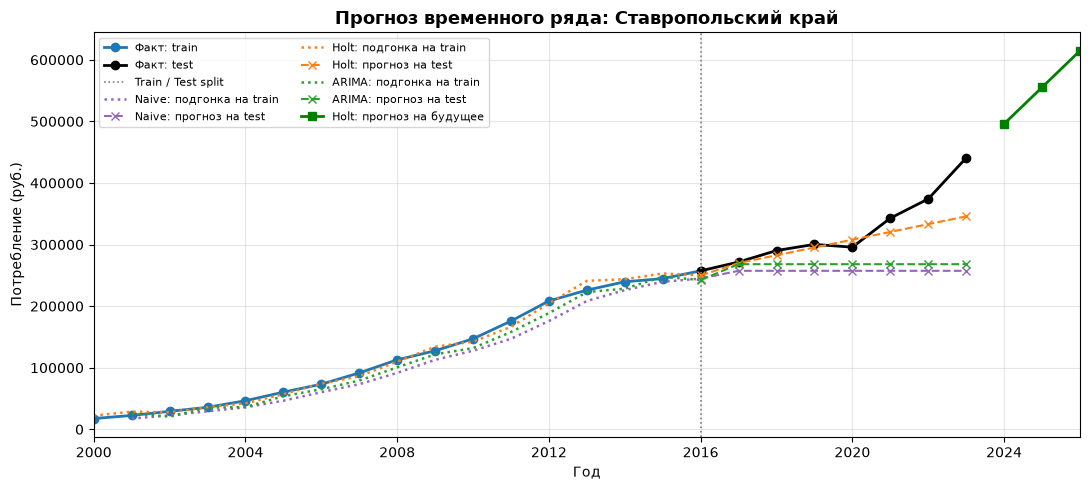


Тверская область: весь ряд train + test
                Факт Выборка  Подгонка Naive  Прогноз Naive  Подгонка Holt  Прогноз Holt  Подгонка ARIMA  Прогноз ARIMA
Год                                                                                                                    
2000-01-01  15387.50   train               —              —       17547.49             —               —              —
2001-01-01  20769.60   train        15387.50              —       26792.78             —        22439.51              —
2002-01-01  26721.60   train        20769.60              —       30373.42             —        19798.56              —
2003-01-01  32782.60   train        26721.60              —       34637.34             —        31057.93              —
2004-01-01  46364.50   train        32782.60              —       39766.05             —        33894.11              —
2005-01-01  64397.80   train        46364.50              —       54787.86             —        54496.30              —

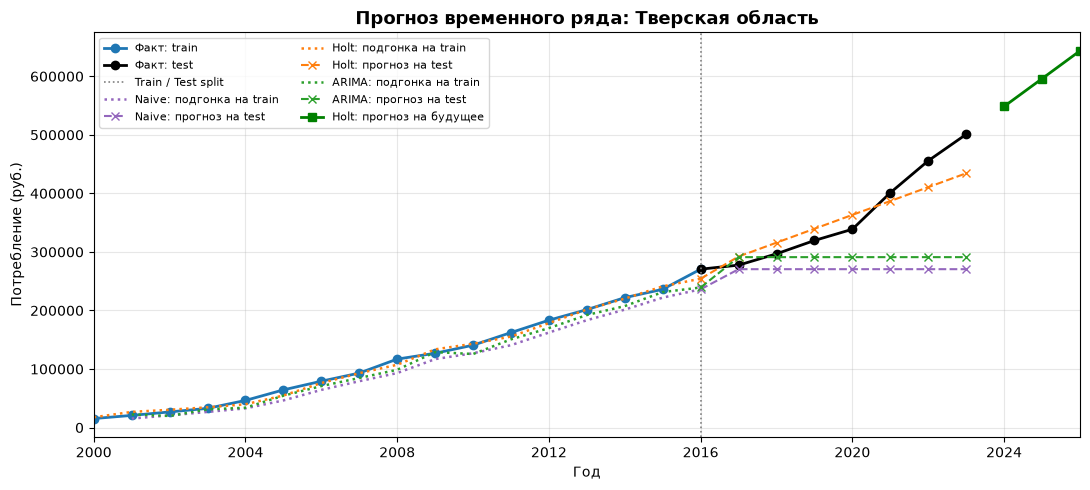


Новгородская область: весь ряд train + test
                Факт Выборка  Подгонка Naive  Прогноз Naive  Подгонка Holt  Прогноз Holt  Подгонка ARIMA  Прогноз ARIMA
Год                                                                                                                    
2000-01-01  20064.60   train               —              —       23723.21             —               —              —
2001-01-01  25017.50   train        20064.60              —       33445.18             —        29687.93              —
2002-01-01  31998.80   train        25017.50              —       34553.67             —        22103.01              —
2003-01-01  37290.10   train        31998.80              —       38663.35             —        38785.69              —
2004-01-01  46100.20   train        37290.10              —       42871.59             —        36218.97              —
2005-01-01  56879.80   train        46100.20              —       52507.56             —        53334.38           

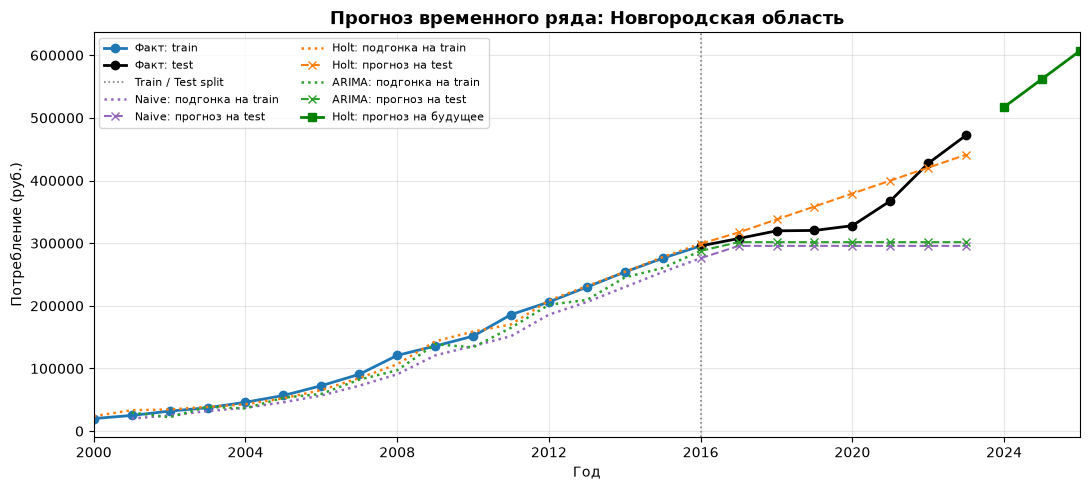


=== ВЫВОДЫ ===
Ставропольский край: лучшая модель — Holt (RMSE=40403.376, MAPE=6.87%). Статистическая модель превзошла бейзлайн.
Тверская область: лучшая модель — Holt (RMSE=34318.486, MAPE=7.42%). Статистическая модель превзошла бейзлайн.
Новгородская область: лучшая модель — Holt (RMSE=30666.013, MAPE=7.63%). Статистическая модель превзошла бейзлайн.


In [12]:
# =========================================================
# Импорты
# =========================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error

# --- sktime (бейзлайн) ---
from sktime.forecasting.naive import NaiveForecaster
from sktime.forecasting.base import ForecastingHorizon

# --- statsmodels ---
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA


# =========================================================
# 1. Данные
# =========================================================
# regions_list сформирован на этапе 3: один представитель каждого кластера.
# Берём исходные ряды из df_long, без добавленных столбцов скользящего среднего.
if not regions_list or len(regions_list) != len(set(regions_list)):
    raise ValueError("Выберите неповторяющиеся регионы на этапе 3")
forecast_source = df_long.pivot(
    index='year', columns='region_name', values='value'
).sort_index()
missing_names = set(regions_list) - set(forecast_source.columns)
if missing_names:
    raise ValueError(f"Регионы отсутствуют в df_long: {sorted(missing_names)}")
forecast_regions = {}
for name in regions_list:
    series = forecast_source[name]
    series = series.copy().sort_index()
    if not isinstance(series.index, pd.DatetimeIndex):
        series.index = pd.to_datetime(series.index.astype(str), format="%Y")
    if series.index.has_duplicates:
        raise ValueError(f"{name}: повторяющиеся годы в индексе")
    series = series.asfreq("YS").astype(float)
    if not np.isfinite(series.to_numpy()).all():
        raise ValueError(f"{name}: ряд содержит пропуски или бесконечные значения")
    forecast_regions[name] = series
if not forecast_regions:
    raise ValueError("Нет выбранных регионов: выполните предыдущие ячейки")


# =========================================================
# 2. Train/test split + горизонт
# =========================================================
# Для 24 наблюдений: 17 лет в train, 7 лет в test.
# Общий горизонт сохраняет не менее 70% каждого ряда для обучения.
HORIZON = min(len(series) - int(np.ceil(0.7 * len(series)))
              for series in forecast_regions.values())
if HORIZON < 1:
    raise ValueError("Недостаточно данных для train/test")
FUTURE_HORIZON = 3

splits = {}
print("=== Разбиение train/test ===")
for name, s in forecast_regions.items():
    n = len(s)
    n_train = n - HORIZON
    train = s.iloc[:n_train].asfreq("YS")
    test  = s.iloc[n_train:].asfreq("YS")
    splits[name] = (train, test)
    print(f"{name}: train {len(train)} точек "
          f"({train.index[0].year}–{train.index[-1].year}), "
          f"test {len(test)} точек ({test.index[0].year}–{test.index[-1].year})")


# =========================================================
# 3. Три модели
# =========================================================
def forecast_naive(train, horizon):
    """NaiveForecaster(strategy='last') — бейзлайн."""
    forecaster = NaiveForecaster(strategy="last")
    forecaster.set_config(remember_data=False)
    forecaster.fit(train)
    fh = ForecastingHorizon(np.arange(1, horizon + 1), is_relative=True)
    return forecaster.predict(fh)


def forecast_holt(train, horizon):
    """Holt с аддитивным трендом, без сезонности."""
    model = ExponentialSmoothing(
        train, trend="add", seasonal=None, initialization_method="estimated"
    ).fit(optimized=True)
    return model.forecast(horizon)


def forecast_arima(train, horizon, order=(0, 1, 1)):
    """Фиксированный кандидат ARIMA; тестовые значения в обучение не входят."""
    model = ARIMA(train, order=order).fit()
    return model.forecast(horizon)


# Общий кандидат ARIMA(0,1,1); порядок не подбирается по тестовой выборке.
MODELS = {
    "Naive": forecast_naive,
    "Holt":  forecast_holt,
    "ARIMA": lambda tr, h: forecast_arima(tr, h, order=(0, 1, 1)),
}


def fitted_on_train(train, model_name):
    """Подгонка на train; параметры Holt/ARIMA оценены по всему train."""
    if model_name == 'Naive':
        # Для первого года предыдущее наблюдение отсутствует.
        return train.shift(1)
    if model_name == 'Holt':
        fitted_model = ExponentialSmoothing(
            train, trend='add', seasonal=None, initialization_method='estimated'
        ).fit(optimized=True)
        return pd.Series(np.asarray(fitted_model.fittedvalues), index=train.index)
    if model_name == 'ARIMA':
        fitted_model = ARIMA(train, order=(0, 1, 1)).fit()
        fitted = pd.Series(np.asarray(fitted_model.fittedvalues), index=train.index)
        # Пропускаем начальные значения с диффузной инициализацией.
        fitted.iloc[:max(1, fitted_model.loglikelihood_burn)] = np.nan
        return fitted
    raise ValueError(f'Неизвестная модель: {model_name}')


# =========================================================
# 4. Метрики
# =========================================================
def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def mape(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    mask = y_true != 0
    if not mask.any():
        return np.nan
    return float(np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100)


# =========================================================
# 5. Оценка на фиксированном train/test
# =========================================================
forecast_results = []
forecasts_test = {}   # для графиков

for name, (train, test) in splits.items():
    forecasts_test[name] = {}
    for mname, func in MODELS.items():
        try:
            pred = np.asarray(func(train, HORIZON), dtype=float)
            if pred.shape != (len(test),) or not np.isfinite(pred).all():
                raise ValueError("Прогноз должен содержать конечные значения для всех лет test")
            forecasts_test[name][mname] = pred
            forecast_results.append({
                "Регион":  name,
                "Модель":  mname,
                "Факт":    round(float(test.iloc[0]), 3) if len(test) else np.nan,
                "Прогноз": round(float(pred[0]), 3) if len(pred) else np.nan,
                "RMSE":    rmse(test.values, pred),
                "MAPE,%":  mape(test.values, pred),
            })
        except Exception as e:
            print(f"[{name}/{mname}] ошибка: {e}")

results_df = pd.DataFrame(forecast_results, columns=[
    "Регион", "Модель", "Факт", "Прогноз", "RMSE", "MAPE,%"
])
missing_regions = set(forecast_regions) - set(results_df["Регион"])
if missing_regions:
    raise RuntimeError(f"Не удалось оценить ни одну модель: {sorted(missing_regions)}")
print("\n=== Оценка моделей на тестовой выборке ===")
print(results_df.to_string(index=False))


# =========================================================
# 6. Устойчивость: Expanding window для лучшей модели региона
# =========================================================
best_per_region = (results_df.dropna(subset=["RMSE"])
                   .sort_values("RMSE")
                   .groupby("Регион", as_index=False).first())

print("\n=== Лучшая модель по каждому региону (по RMSE) ===")
print(best_per_region[["Регион", "Модель", "RMSE", "MAPE,%"]].to_string(index=False))

stability_rows = []
for name, s in forecast_regions.items():
    best_name = best_per_region.loc[
        best_per_region["Регион"] == name, "Модель"].iloc[0]
    func = MODELS[best_name]

    # Expanding window: train на первых k точках, прогноз на (k+1)-ю
    for k in range(len(splits[name][0]), len(s)):
        train_k = s.iloc[:k].asfreq("YS")
        true_next = float(s.iloc[k])
        try:
            pred_val = float(np.asarray(func(train_k, 1), dtype=float)[0])
            if not np.isfinite(pred_val):
                raise ValueError("Одношаговый прогноз содержит неконечное значение")
            stability_rows.append({
                "Регион": name,
                "Модель": best_name,
                "Итерация": k,
                "Год": s.index[k].year,
                "Train_n": k,
                "Прогноз": pred_val,
                "Факт":   true_next,
                "|Ошибка|": abs(pred_val - true_next),
                "MAPE_1шаг,%": mape([true_next], [pred_val]),
            })
        except Exception as e:
            print(f"[{name}/{best_name}/iter{k}] ошибка: {e}")

stab_df = pd.DataFrame(stability_rows, columns=[
    "Регион", "Модель", "Итерация", "Год", "Train_n", "Прогноз", "Факт",
    "|Ошибка|", "MAPE_1шаг,%",
])
print("\n=== Устойчивость прогноза (expanding window) ===")
print(stab_df.to_string(index=False))

# Сводка: фикс. train/test vs средняя по expanding window
print("\n=== Сравнение фикс. test и expanding window ===")
cmp_rows = []
for name in forecast_regions:
    best_name = best_per_region.loc[
        best_per_region["Регион"] == name, "Модель"].iloc[0]
    fixed_mape = results_df[(results_df["Регион"] == name)
                            & (results_df["Модель"] == best_name)]["MAPE,%"].iloc[0]
    win = stab_df[stab_df["Регион"] == name]
    exp_mape = round(win["MAPE_1шаг,%"].mean(), 2) if len(win) else np.nan
    cmp_rows.append({
        "Регион": name, "Модель": best_name,
        "RMSE_fixed": best_per_region.loc[
            best_per_region["Регион"] == name, "RMSE"].iloc[0],
        "RMSE_expanding": rmse(win["Факт"], win["Прогноз"]) if len(win) else np.nan,
        "Проверено лет": len(win),
        "MAPE_fixed,%": fixed_mape,
        "MAPE_expanding(avg),%": exp_mape,
        "Δ, п.п.": round(exp_mape - fixed_mape, 2) if pd.notna(exp_mape) else np.nan,
    })
cmp_df = pd.DataFrame(cmp_rows)
print(cmp_df.to_string(index=False))
print("Expanding window использует обновление данных и прогноз на один год; "
      "фиксированный прогноз сделан сразу на весь test. Это разные режимы оценки. "
      "Лучшая модель выбрана по этому же test, поэтому сравнение носит описательный характер.")


# =========================================================
# 7. Визуализация: история + прогноз на тест + прогноз в будущее
# =========================================================
forecasts_future = {}
full_series_tables = {}
fitted_train = {}
model_colors = {"Naive": "tab:purple", "Holt": "tab:orange", "ARIMA": "tab:green"}
for name, s in forecast_regions.items():
    train, test = splits[name]
    fig, ax = plt.subplots(figsize=(11, 5))

    # Подгонка по всему train служит визуализацией, метрики считаются на test.
    fitted_train[name] = {
        mname: fitted_on_train(train, mname)
        for mname in forecasts_test[name]
    }
    # Полный ряд, подгонка на train и отложенные прогнозы на test.
    full_table = pd.DataFrame({'Факт': s})
    full_table['Выборка'] = 'train'
    full_table.loc[test.index, 'Выборка'] = 'test'
    for mname, pred_arr in forecasts_test[name].items():
        full_table[f'Подгонка {mname}'] = fitted_train[name][mname]
        full_table[f'Прогноз {mname}'] = pd.Series(pred_arr, index=test.index)
    full_series_tables[name] = full_table
    print(f'\n{name}: весь ряд train + test')
    print(full_table.rename_axis('Год').to_string(
        float_format=lambda value: f'{value:.2f}', na_rep='—',
        formatters=None,
    ))

    # 7.1 Весь исходный ряд; train и test выделены цветом.
    ax.plot(train.index, train.values, marker="o", lw=2,
            color="tab:blue", label="Факт: train")
    test_with_boundary = pd.concat([train.iloc[-1:], test])
    ax.plot(test_with_boundary.index, test_with_boundary.values, marker="o", lw=2,
            color="black", label="Факт: test")

    # 7.2 Разделение train / test
    ax.axvline(x=train.index[-1], color="gray", ls=":", lw=1.2,
               label="Train / Test split")

    # 7.3 Подгонка на train и прогноз на test одним цветом для каждой модели.
    for mname in MODELS:
        pred_arr = forecasts_test[name].get(mname)
        if pred_arr is None or len(test) == 0:
            continue
        pred_ser = pd.Series(pred_arr[:len(test)], index=test.index)
        train_fit = fitted_train[name][mname]
        ax.plot(train_fit.index, train_fit.values, ls=":", lw=1.8,
                color=model_colors[mname], label=f"{mname}: подгонка на train")
        # Соединяем последний fitted с первым прогнозом без разрыва линии.
        test_prediction = pd.concat([train_fit.iloc[-1:], pred_ser])
        ax.plot(test_prediction.index, test_prediction.values, marker="x", ls="--",
                color=model_colors[mname], label=f"{mname}: прогноз на test")

    # 7.4 Прогноз в будущее — от лучшей модели, обученной на полном ряду
    best_name = best_per_region.loc[
        best_per_region["Регион"] == name, "Модель"].iloc[0]
    try:
        future_pred = np.asarray(
            MODELS[best_name](s.asfreq("YS"), FUTURE_HORIZON), dtype=float)
        future_idx = pd.date_range(
            s.index[-1] + pd.DateOffset(years=1),
            periods=FUTURE_HORIZON, freq="YS")
        if future_pred.shape != (FUTURE_HORIZON,) or not np.isfinite(future_pred).all():
            raise ValueError("Некорректный прогноз на будущий период")
        forecasts_future[name] = pd.Series(future_pred, index=future_idx, name=best_name)
        ax.plot(future_idx, future_pred, marker="s", ls="-", lw=2,
                color="green", label=f"{best_name}: прогноз на будущее")
    except Exception as e:
        print(f"[{name}] future forecast error: {e}")

    ax.set_title(f"Прогноз временного ряда: {name}", fontsize=13, fontweight="bold")
    ax.set_xlabel("Год")
    ax.set_ylabel("Потребление (руб.)")
    ax.set_xlim(s.index[0], s.index[-1] + pd.DateOffset(years=FUTURE_HORIZON))
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best", fontsize=8, ncol=2)
    plt.tight_layout()
    plt.show()
    plt.close(fig)


# =========================================================
# 8. Выводы
# =========================================================
print("\n=== ВЫВОДЫ ===")
for name in forecast_regions:
    row = results_df[results_df["Регион"] == name].dropna(subset=["RMSE"])
    row = row.sort_values("RMSE")
    best = row.iloc[0]
    naive_rows = results_df[(results_df["Регион"] == name)
                            & (results_df["Модель"] == "Naive")]
    naive_rmse = naive_rows["RMSE"].iloc[0] if len(naive_rows) else np.nan
    better_than_naive = best["Модель"] != "Naive" and best["RMSE"] < naive_rmse
    msg = (f"{name}: лучшая модель — {best['Модель']} "
           f"(RMSE={best['RMSE']:.3f}, MAPE={best['MAPE,%']:.2f}%). ")
    if pd.isna(naive_rmse):
        msg += "Бейзлайн не рассчитан: сравнение с ним недоступно."
    elif better_than_naive:
        msg += "Статистическая модель превзошла бейзлайн."
    else:
        msg += ("На выбранной тестовой выборке бейзлайн Naive не превзойдён.")
    print(msg)

## Этап 6. Анализ ошибок (5 баллов)

Для лучшей модели каждого региона:
1. Найти точки с наибольшими ошибками (топ‑5 по абсолютной ошибке).
2. Представить результаты в виде таблицы или графика.
3. Сопоставить эти годы с известными экономическими событиями (кризис 2008, падение цен на нефть 2014, пандемия 2020, санкционное давление 2022 и т.п.).
4. Сформулировать гипотезы, почему модель ошиблась в эти периоды (например, структурные сдвиги, резкие изменения тренда, внешние шоки).

---

Топ‑5 ошибок лучшей модели каждого региона на тестовой выборке:


,Регион,Модель,Год,Факт,Прогноз,Ошибка,Абсолютная ошибка,"Ошибка,%",Место
0,Ставропольский край,Holt,2023,440721.9,345806.70,94915.20,94915.20,21.54,1
1,Ставропольский край,Holt,2022,374178.3,333172.20,41006.10,41006.10,10.96,2
2,Ставропольский край,Holt,2021,342937.6,320537.70,22399.90,22399.90,6.53,3
3,Ставропольский край,Holt,2020,295748.7,307903.20,-12154.50,12154.50,4.11,4
4,Ставропольский край,Holt,2018,290313.2,282634.20,7679.00,7679.00,2.65,5
7,Тверская область,Holt,2023,500882.3,434356.46,66525.84,66525.84,13.28,1
8,Тверская область,Holt,2022,455758.8,410661.32,45097.48,45097.48,9.90,2
9,Тверская область,Holt,2020,338741.1,363271.03,-24529.93,24529.93,7.24,3
10,Тверская область,Holt,2019,319572.3,339575.88,-20003.58,20003.58,6.26,4
11,Тверская область,Holt,2018,296808.8,315880.74,-19071.94,19071.94,6.43,5


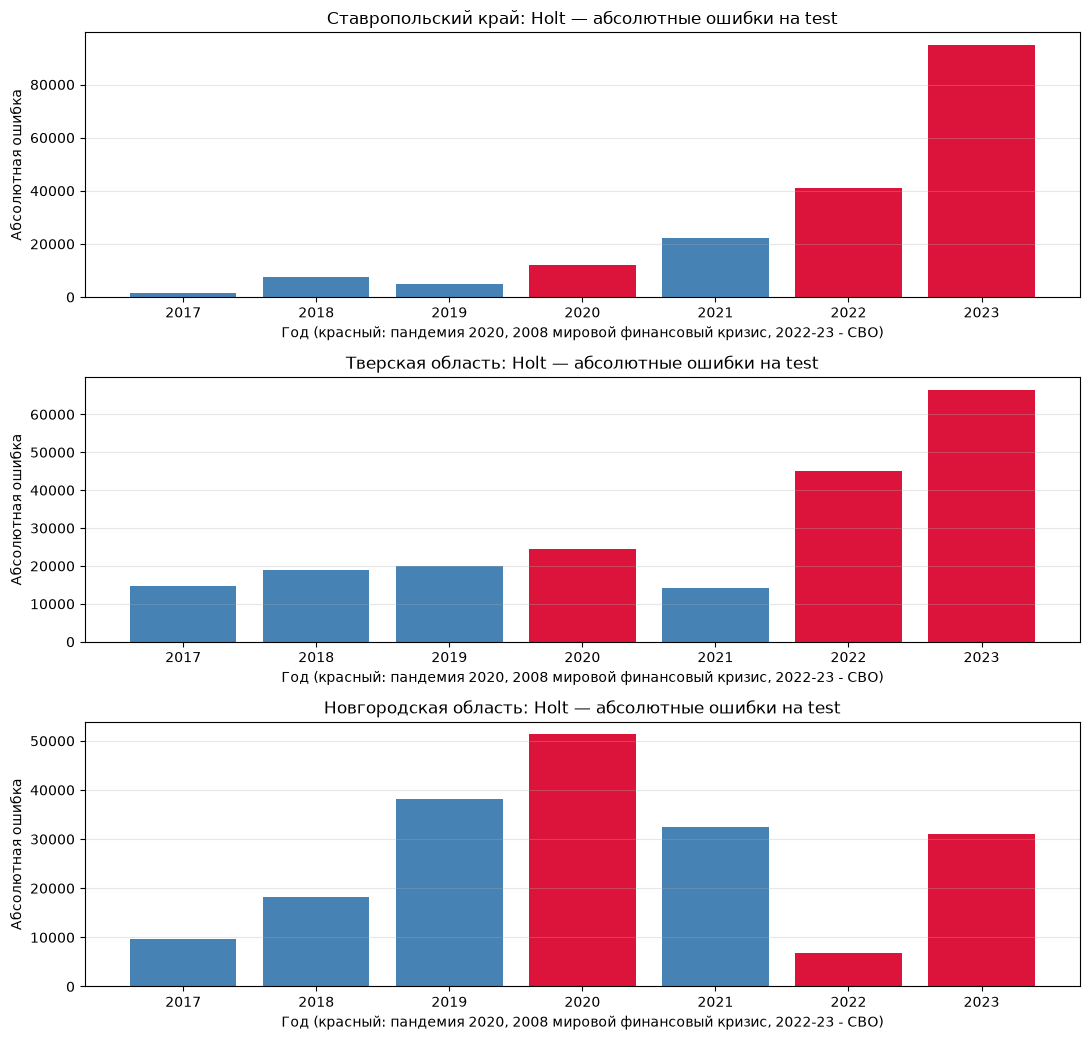

Историческая диагностика событий: отдельные однолетние прогнозы


,Регион,Модель,Год,Событие,Обучение до,Факт,Прогноз на 1 год,Ошибка,Абсолютная ошибка,"Ошибка,%"
0,Ставропольский край,Holt,2008,Начало мирового финансового кризиса,2007,112861.1,109867.89,2993.21,2993.21,2.65
1,Ставропольский край,Holt,2009,Спад после кризиса 2008 года,2008,127607.3,134112.70,-6505.40,6505.40,5.10
2,Ставропольский край,Holt,2020,Пандемия COVID-19 и ограничения активности,2019,295748.7,310324.60,-14575.90,14575.90,4.93
3,Тверская область,Holt,2008,Начало мирового финансового кризиса,2007,116965.0,107060.20,9904.80,9904.80,8.47
4,Тверская область,Holt,2009,Спад после кризиса 2008 года,2008,126953.3,140803.10,-13849.80,13849.80,10.91
5,Тверская область,Holt,2020,Пандемия COVID-19 и ограничения активности,2019,338741.1,337342.58,1398.52,1398.52,0.41
6,Новгородская область,Holt,2008,Начало мирового финансового кризиса,2007,120888.3,108974.60,11913.70,11913.70,9.86
7,Новгородская область,Holt,2009,Спад после кризиса 2008 года,2008,135828.2,151038.60,-15210.40,15210.40,11.20
8,Новгородская область,Holt,2020,Пандемия COVID-19 и ограничения активности,2019,327910.6,326893.50,1017.10,1017.10,0.31



Ставропольский край: максимальная ошибка на test — 2023 год, 94915.20 (21.54%).
2020: место 4 из 7 по абсолютной ошибке, входит в топ‑5; прогноз переоценил показатель. Абсолютная ошибка — 12154.50.

Тверская область: максимальная ошибка на test — 2023 год, 66525.84 (13.28%).
2020: место 3 из 7 по абсолютной ошибке, входит в топ‑5; прогноз переоценил показатель. Абсолютная ошибка — 24529.93.

Новгородская область: максимальная ошибка на test — 2020 год, 51326.03 (15.65%).
2020: место 1 из 7 по абсолютной ошибке, входит в топ‑5; прогноз переоценил показатель. Абсолютная ошибка — 51326.03.


In [13]:
# Ошибки сохранённого тестового прогноза: без повторного обучения.
error_frames = []
for name in forecast_regions:
    best_name = best_per_region.loc[
        best_per_region["Регион"].eq(name), "Модель"
    ].iloc[0]
    _, test = splits[name]
    pred = np.asarray(forecasts_test[name][best_name], dtype=float)
    if pred.shape != (len(test),):
        raise ValueError(f"{name}: длина прогноза не совпадает с test")
    errors = pd.DataFrame({
        "Регион": name, "Модель": best_name,
        "Год": test.index.year, "Факт": test.to_numpy(), "Прогноз": pred,
    })
    errors["Ошибка"] = errors["Факт"] - errors["Прогноз"]
    errors["Абсолютная ошибка"] = errors["Ошибка"].abs()
    errors["Ошибка,%"] = (
        errors["Абсолютная ошибка"] / errors["Факт"].abs().replace(0, np.nan) * 100
    )
    errors = errors.sort_values(
        ["Абсолютная ошибка", "Год"], ascending=[False, True]
    ).reset_index(drop=True)
    errors["Место"] = np.arange(1, len(errors) + 1)
    error_frames.append(errors)

errors_df = pd.concat(error_frames, ignore_index=True)
top5_errors_df = errors_df.loc[errors_df["Место"].le(5)].copy()
print("Топ‑5 ошибок лучшей модели каждого региона на тестовой выборке:")
display(top5_errors_df.round(2))

fig, axes = plt.subplots(
    len(forecast_regions), 1, figsize=(11, 3.5 * len(forecast_regions)), squeeze=False
)
for ax, (name, group) in zip(axes[:, 0], errors_df.groupby("Регион", sort=False)):
    group = group.sort_values("Год")
    colors = ["crimson" if year in [2008,2020,2022,2023] else "steelblue" for year in group["Год"]]
    ax.bar(group["Год"], group["Абсолютная ошибка"], color=colors)
    ax.set_title(f"{name}: {group['Модель'].iloc[0]} — абсолютные ошибки на test")
    ax.set_xticks(group["Год"])
    ax.set_ylabel("Абсолютная ошибка")
    ax.set_xlabel("Год (красный: пандемия 2020, 2008 мировой финансовый кризис, 2022-23 - СВО)")
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
plt.close(fig)

# Сопоставление событий при одинаковом однолетнем горизонте.
event_labels = {
    2008: "Начало мирового финансового кризиса",
    2009: "Спад после кризиса 2008 года",
    2020: "Пандемия COVID-19 и ограничения активности",
}
event_rows = []
for name, series in forecast_regions.items():
    best_name = best_per_region.loc[
        best_per_region["Регион"].eq(name), "Модель"
    ].iloc[0]
    for year, event in event_labels.items():
        date = pd.Timestamp(year=year, month=1, day=1)
        history = series.loc[series.index < date]
        if date not in series.index or len(history) < 4:
            continue
        actual = float(series.loc[date])
        prediction = float(np.asarray(MODELS[best_name](history, 1))[0])
        if not np.isfinite(prediction):
            raise ValueError(f"{name}, {year}: некорректный прогноз")
        event_rows.append({
            "Регион": name, "Модель": best_name, "Год": year,
            "Событие": event, "Обучение до": history.index[-1].year,
            "Факт": actual, "Прогноз на 1 год": prediction,
            "Ошибка": actual - prediction,
            "Абсолютная ошибка": abs(actual - prediction),
            "Ошибка,%": mape([actual], [prediction]),
        })
event_errors_df = pd.DataFrame(event_rows)
print("Историческая диагностика событий: отдельные однолетние прогнозы")
display(event_errors_df.round(2))

for name, group in errors_df.groupby("Регион", sort=False):
    worst = group.loc[group["Место"].eq(1)].iloc[0]
    print(f"\n{name}: максимальная ошибка на test — {int(worst['Год'])} год, "
          f"{worst['Абсолютная ошибка']:.2f} ({worst['Ошибка,%']:.2f}%).")
    pandemic = group.loc[group["Год"].eq(2020)]
    if not pandemic.empty:
        row = pandemic.iloc[0]
        position = int(row["Место"])
        inclusion = "входит" if position <= 5 else "не входит"
        direction = "недооценил" if row["Ошибка"] > 0 else "переоценил" if row["Ошибка"] < 0 else "точно предсказал"
        print(f"2020: место {position} из {len(group)} по абсолютной ошибке, "
              f"{inclusion} в топ‑5; прогноз {direction} показатель. "
              f"Абсолютная ошибка — {row['Абсолютная ошибка']:.2f}.")



## Этап 7. Индивидуальные рекомендации (4 балла)

На основе прогнозов сформулировать 2–3 рекомендации **для каждого региона отдельно**.

**Требования:**
- Рекомендации должны быть конкретными и опираться на цифры прогноза (например, ожидаемый темп роста, прогнозируемый уровень потребления).
- Не допускаются общие фразы, которые можно применить к любому региону.
- Каждая рекомендация должна быть привязана к особенностям именно этого региона (тип динамики, уровень волатильности, тренд).

Пример плохой рекомендации: «Развивать социальную сферу».  
Пример хорошей: «Учитывая прогнозируемое замедление темпов роста потребления в 2024–2026 гг. и высокую волатильность ряда, региону X целесообразно создать стабилизационный фонд на уровне не менее Y% от среднегодового потребления для сглаживания колебаний».

---

## Этап 8. Выводы по проекту (2 балла)

Обобщить результаты:
- Какие группы регионов выделились и чем они отличаются.
- Какая модель оказалась наиболее эффективной для каждого типа регионов и почему.
- Какие факторы, по вашему мнению, влияют на точность прогноза (структурные сдвиги, внешние шоки, длина ряда, волатильность и т.д.).
- Ограничения исследования: что модель не учитывает, в каких случаях прогноз может быть ненадёжным.
- Возможные направления улучшения: дополнительные признаки, учёт инфляции (переход к реальным значениям), включение внешних регрессоров, ансамбли моделей и т.п.

---

